# PACK analysis in R3

This notebook starts the round 3 protocol for PACK, using the R3 data files to inspect price shape, trade activity, spread behavior, and lag structure. The short name PACK refers to `HYDROGEL_PACK` in the data. Day 2 is held out and excluded here for later backtest validation.

In [15]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams['figure.figsize'] = (16, 6)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

def find_data_dir() -> Path:
    for candidate in (Path('R3/Data'), Path('../Data'), Path('Data')):
        if candidate.exists():
            return candidate
    raise FileNotFoundError('Could not find R3/Data from the current notebook location.')

DATA_DIR = find_data_dir()
PACK = 'HYDROGEL_PACK'

holdout_day = 2
price_files = [path for path in sorted(DATA_DIR.glob('prices_round_3_day_*.csv')) if int(path.stem.split('_day_')[-1]) != holdout_day]
trade_files = [path for path in sorted(DATA_DIR.glob('trades_round_3_day_*.csv')) if int(path.stem.split('_day_')[-1]) != holdout_day]

prices = pd.concat([pd.read_csv(path, sep=';') for path in price_files], ignore_index=True)
trades = pd.concat([pd.read_csv(path, sep=';').assign(day=int(path.stem.split('_day_')[-1])) for path in trade_files], ignore_index=True)

pack_prices = prices.loc[prices['product'] == PACK].copy()
pack_trades = trades.loc[trades['symbol'] == PACK].copy()

print('Data dir:', DATA_DIR)
print('Price rows:', len(prices), 'Trade rows:', len(trades))
print('Products:', sorted(prices['product'].unique().tolist()))
print('Trade symbols:', sorted(trades['symbol'].unique().tolist()))
print('PACK price rows:', len(pack_prices))
print('PACK trade rows:', len(pack_trades))
display(pack_prices.head())
display(pack_trades.head())

Data dir: ../Data
Price rows: 240000 Trade rows: 2715
Products: ['HYDROGEL_PACK', 'VELVETFRUIT_EXTRACT', 'VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']
Trade symbols: ['HYDROGEL_PACK', 'VELVETFRUIT_EXTRACT', 'VEV_4000', 'VEV_4500', 'VEV_5000', 'VEV_5100', 'VEV_5200', 'VEV_5300', 'VEV_5400', 'VEV_5500', 'VEV_6000', 'VEV_6500']
PACK price rows: 20000
PACK trade rows: 699


,day,timestamp,product,bid_price_1,bid_volume_1,bid_price_2,bid_volume_2,bid_price_3,bid_volume_3,ask_price_1,ask_volume_1,ask_price_2,ask_volume_2,ask_price_3,ask_volume_3,mid_price,profit_and_loss
7,0,0,HYDROGEL_PACK,9992,15,9990.0,30.0,NaN,NaN,10008,15,10010.0,30.0,NaN,NaN,10000.0,0.0
19,0,100,HYDROGEL_PACK,9992,13,9990.0,30.0,NaN,NaN,10008,13,10011.0,30.0,NaN,NaN,10000.0,0.0
24,0,200,HYDROGEL_PACK,9995,13,9992.0,21.0,NaN,NaN,10011,13,10013.0,21.0,NaN,NaN,10003.0,0.0
41,0,300,HYDROGEL_PACK,9994,11,9992.0,23.0,NaN,NaN,10010,11,10013.0,23.0,NaN,NaN,10002.0,0.0
54,0,400,HYDROGEL_PACK,9995,13,9993.0,23.0,NaN,NaN,10011,13,10014.0,23.0,NaN,NaN,10003.0,0.0


,timestamp,buyer,seller,symbol,currency,price,quantity,day
7,8000,NaN,NaN,HYDROGEL_PACK,XIRECS,10018.0,6,0
10,10100,NaN,NaN,HYDROGEL_PACK,XIRECS,10014.0,5,0
18,15300,NaN,NaN,HYDROGEL_PACK,XIRECS,10026.0,3,0
20,15700,NaN,NaN,HYDROGEL_PACK,XIRECS,10009.0,2,0
21,16400,NaN,NaN,HYDROGEL_PACK,XIRECS,10009.0,4,0


In [16]:
pack_prices = pack_prices.sort_values(['day', 'timestamp']).reset_index(drop=True)
pack_trades = pack_trades.sort_values(['day', 'timestamp']).reset_index(drop=True)

book = pack_prices.assign(
    spread=pack_prices['ask_price_1'] - pack_prices['bid_price_1'],
    imbalance=(pack_prices['bid_volume_1'] - pack_prices['ask_volume_1']) / (pack_prices['bid_volume_1'] + pack_prices['ask_volume_1']),
    microprice=(pack_prices['ask_price_1'] * pack_prices['bid_volume_1'] + pack_prices['bid_price_1'] * pack_prices['ask_volume_1']) / (pack_prices['bid_volume_1'] + pack_prices['ask_volume_1']),
)
book['mid_change'] = book.groupby('day')['mid_price'].diff()
book['pct_change'] = book.groupby('day')['mid_price'].pct_change()
book['next_mid_change'] = book.groupby('day')['mid_price'].shift(-1) - book['mid_price']

trade_mid = pack_trades.merge(
    book[['day', 'timestamp', 'mid_price', 'spread', 'imbalance', 'microprice']],
    on=['day', 'timestamp'],
    how='left',
)
trade_mid['edge_vs_mid'] = trade_mid['price'] - trade_mid['mid_price']
trade_mid['notional'] = trade_mid['price'] * trade_mid['quantity']

daily_summary = book.groupby('day').agg(
    observations=('timestamp', 'size'),
    start_mid=('mid_price', 'first'),
    end_mid=('mid_price', 'last'),
    low_mid=('mid_price', 'min'),
    high_mid=('mid_price', 'max'),
    mean_mid=('mid_price', 'mean'),
    median_mid=('mid_price', 'median'),
    std_mid=('mid_price', 'std'),
    avg_spread=('spread', 'mean'),
    p90_spread=('spread', lambda s: s.quantile(0.9)),
    avg_imbalance=('imbalance', 'mean'),
)
daily_summary['mid_change'] = daily_summary['end_mid'] - daily_summary['start_mid']

trade_summary = trade_mid.groupby('day').agg(
    trades=('timestamp', 'size'),
    qty=('quantity', 'sum'),
    notional=('notional', 'sum'),
)
trade_summary['vwap'] = trade_summary['notional'] / trade_summary['qty']

print('PACK price feature snapshot:')
display(book[['mid_price', 'spread', 'imbalance', 'microprice']].describe().T)
print('PACK daily summary:')
display(daily_summary)
print('PACK trade summary:')
display(trade_summary)
print('First few matched trades:')
display(trade_mid[['day', 'timestamp', 'price', 'mid_price', 'edge_vs_mid', 'quantity']].head())

PACK price feature snapshot:


,count,mean,std,min,25%,50%,75%,max
mid_price,20000.0,9991.508600,32.068355,9908.500000,9966.0,9994.0,10013.0,10079.000000
spread,20000.0,15.713700,1.477309,7.000000,16.0,16.0,16.0,17.000000
imbalance,20000.0,0.000340,0.058284,-0.578947,0.0,0.0,0.0,0.578947
microprice,20000.0,9991.507444,32.067408,9908.500000,9966.0,9994.0,10013.0,10079.000000


PACK daily summary:


,observations,start_mid,end_mid,low_mid,high_mid,mean_mid,median_mid,std_mid,avg_spread,p90_spread,avg_imbalance,mid_change
day,,,,,,,,,,,,
0,10000,10000.0,9958.0,9928.0,10071.0,9990.9621,9991.0,25.328358,15.7010,16.0,0.000862,-42.0
1,10000,9958.0,10015.0,9908.5,10079.0,9992.0551,9999.0,37.613011,15.7264,16.0,-0.000181,57.0


PACK trade summary:


,trades,qty,notional,vwap
day,,,,
0,324,1349,13476975.0,9990.344700
1,375,1485,14841524.0,9994.292256


First few matched trades:


,day,timestamp,price,mid_price,edge_vs_mid,quantity
0,0,8000,10018.0,10014.0,4.0,6
1,0,10100,10014.0,10006.0,8.0,5
2,0,15300,10026.0,10017.5,8.5,3
3,0,15700,10009.0,10017.0,-8.0,2
4,0,16400,10009.0,10017.0,-8.0,4


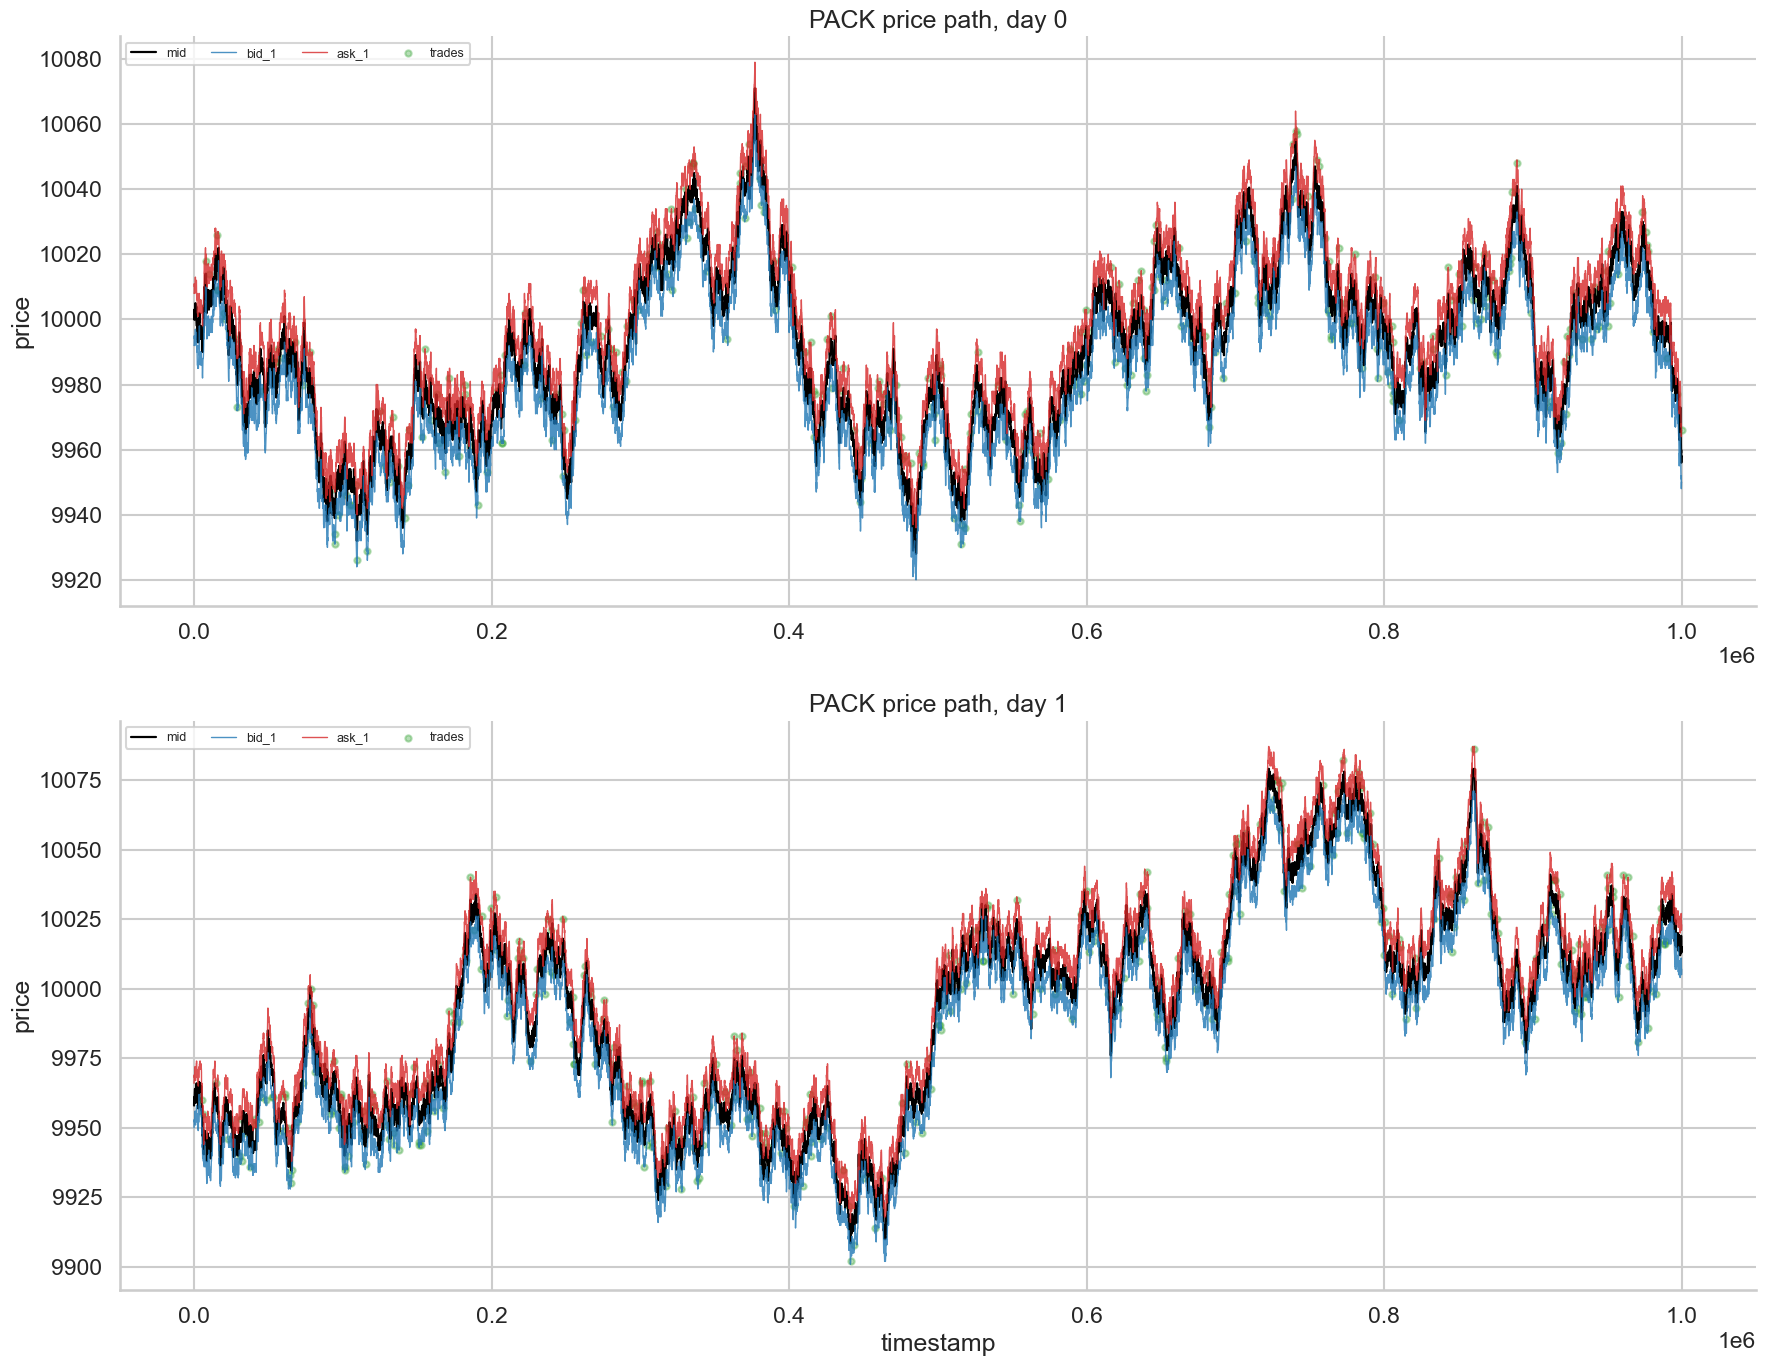

In [17]:
days = sorted(book['day'].unique().tolist())
fig, axes = plt.subplots(len(days), 1, figsize=(18, 14), sharex=False)

for ax, day in zip(axes, days):
    day_prices = book.loc[book['day'] == day]
    day_trades = trade_mid.loc[trade_mid['day'] == day]

    ax.plot(day_prices['timestamp'], day_prices['mid_price'], color='black', lw=1.6, label='mid')
    ax.plot(day_prices['timestamp'], day_prices['bid_price_1'], color='#1f77b4', lw=1.0, alpha=0.8, label='bid_1')
    ax.plot(day_prices['timestamp'], day_prices['ask_price_1'], color='#d62728', lw=1.0, alpha=0.8, label='ask_1')
    ax.scatter(day_trades['timestamp'], day_trades['price'], s=20, color='#2ca02c', alpha=0.35, label='trades')
    ax.set_title(f'PACK price path, day {day}')
    ax.set_ylabel('price')
    ax.legend(loc='upper left', ncol=4, fontsize=9)

axes[-1].set_xlabel('timestamp')
plt.tight_layout()

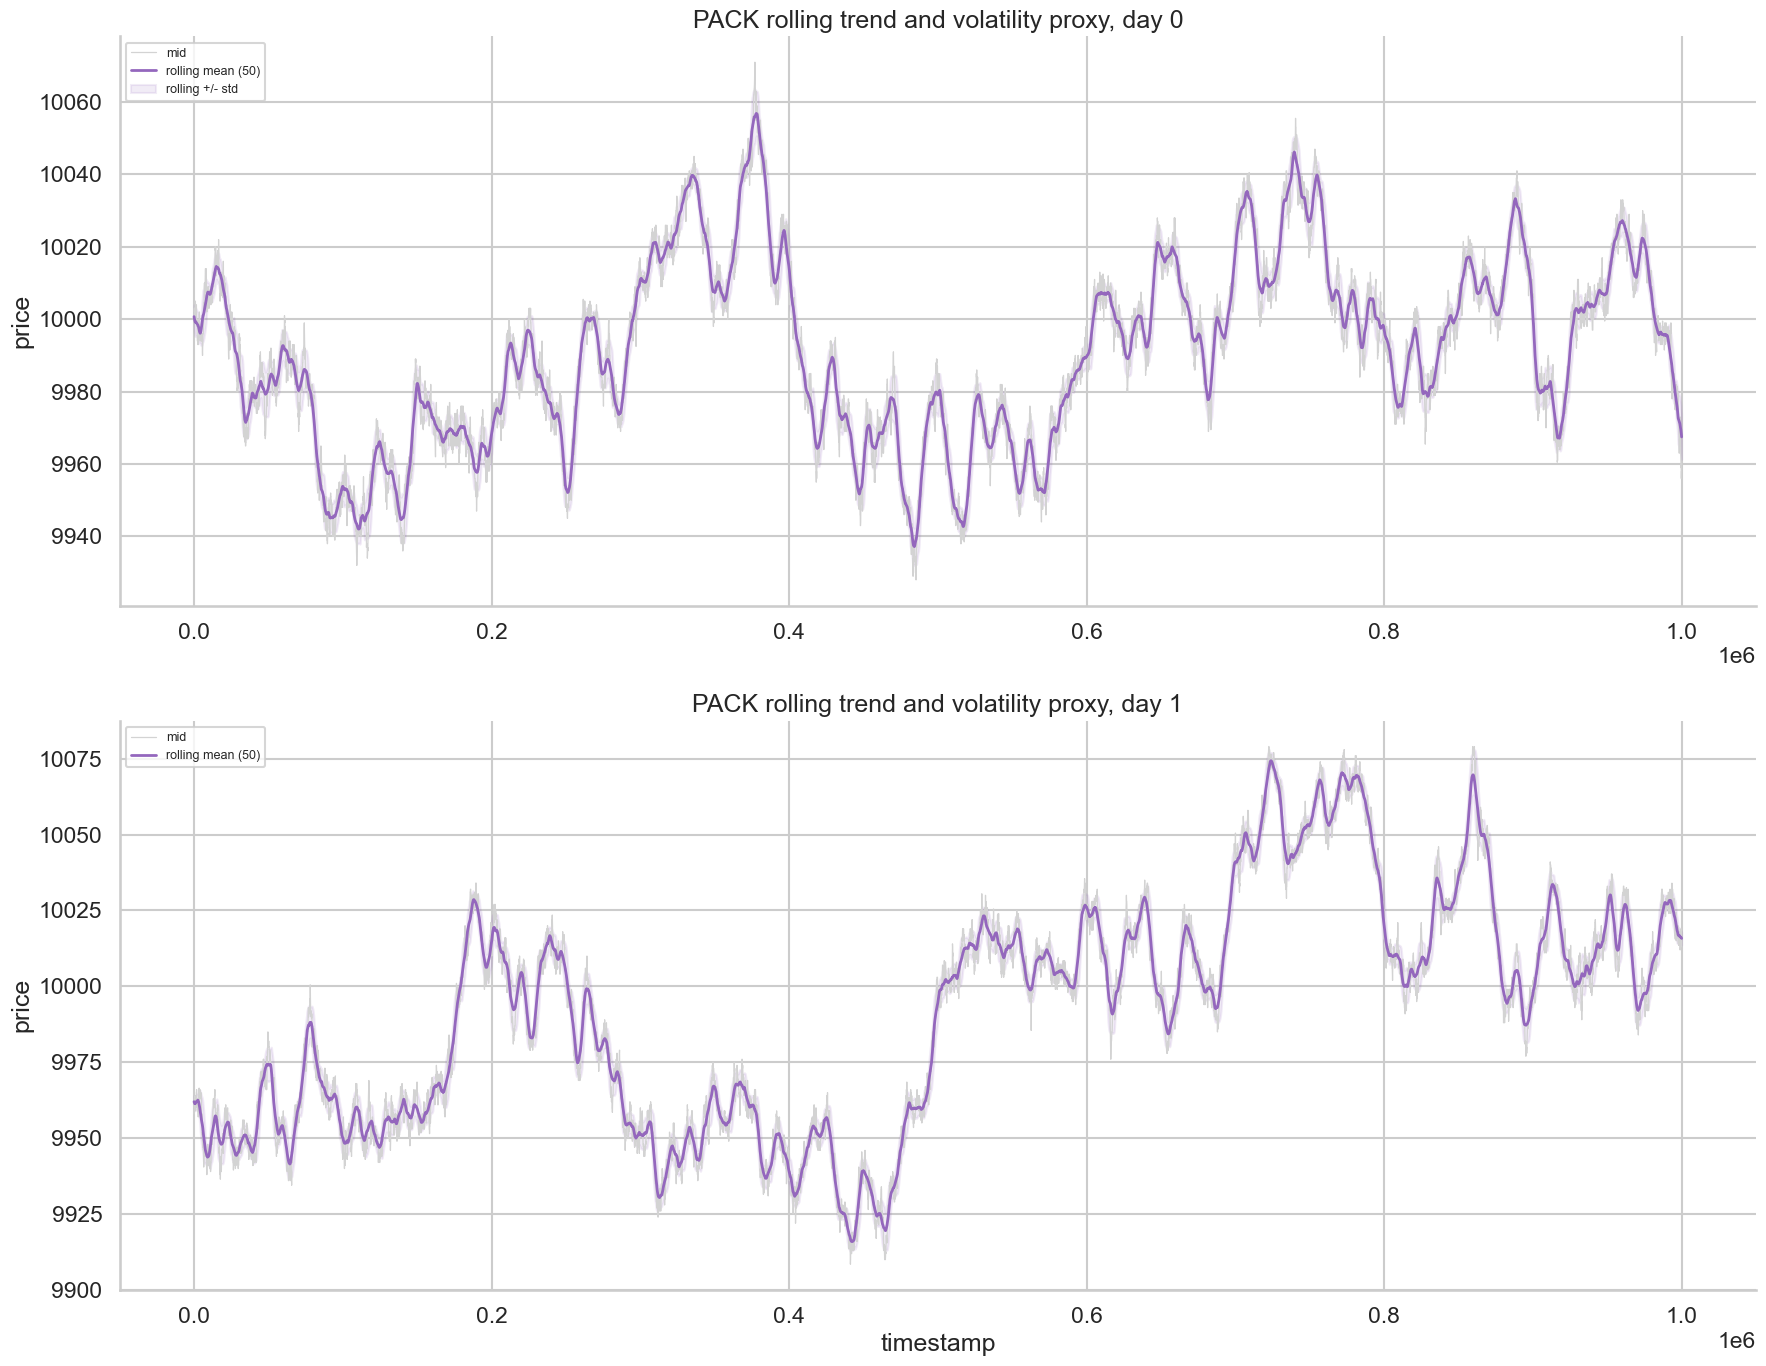

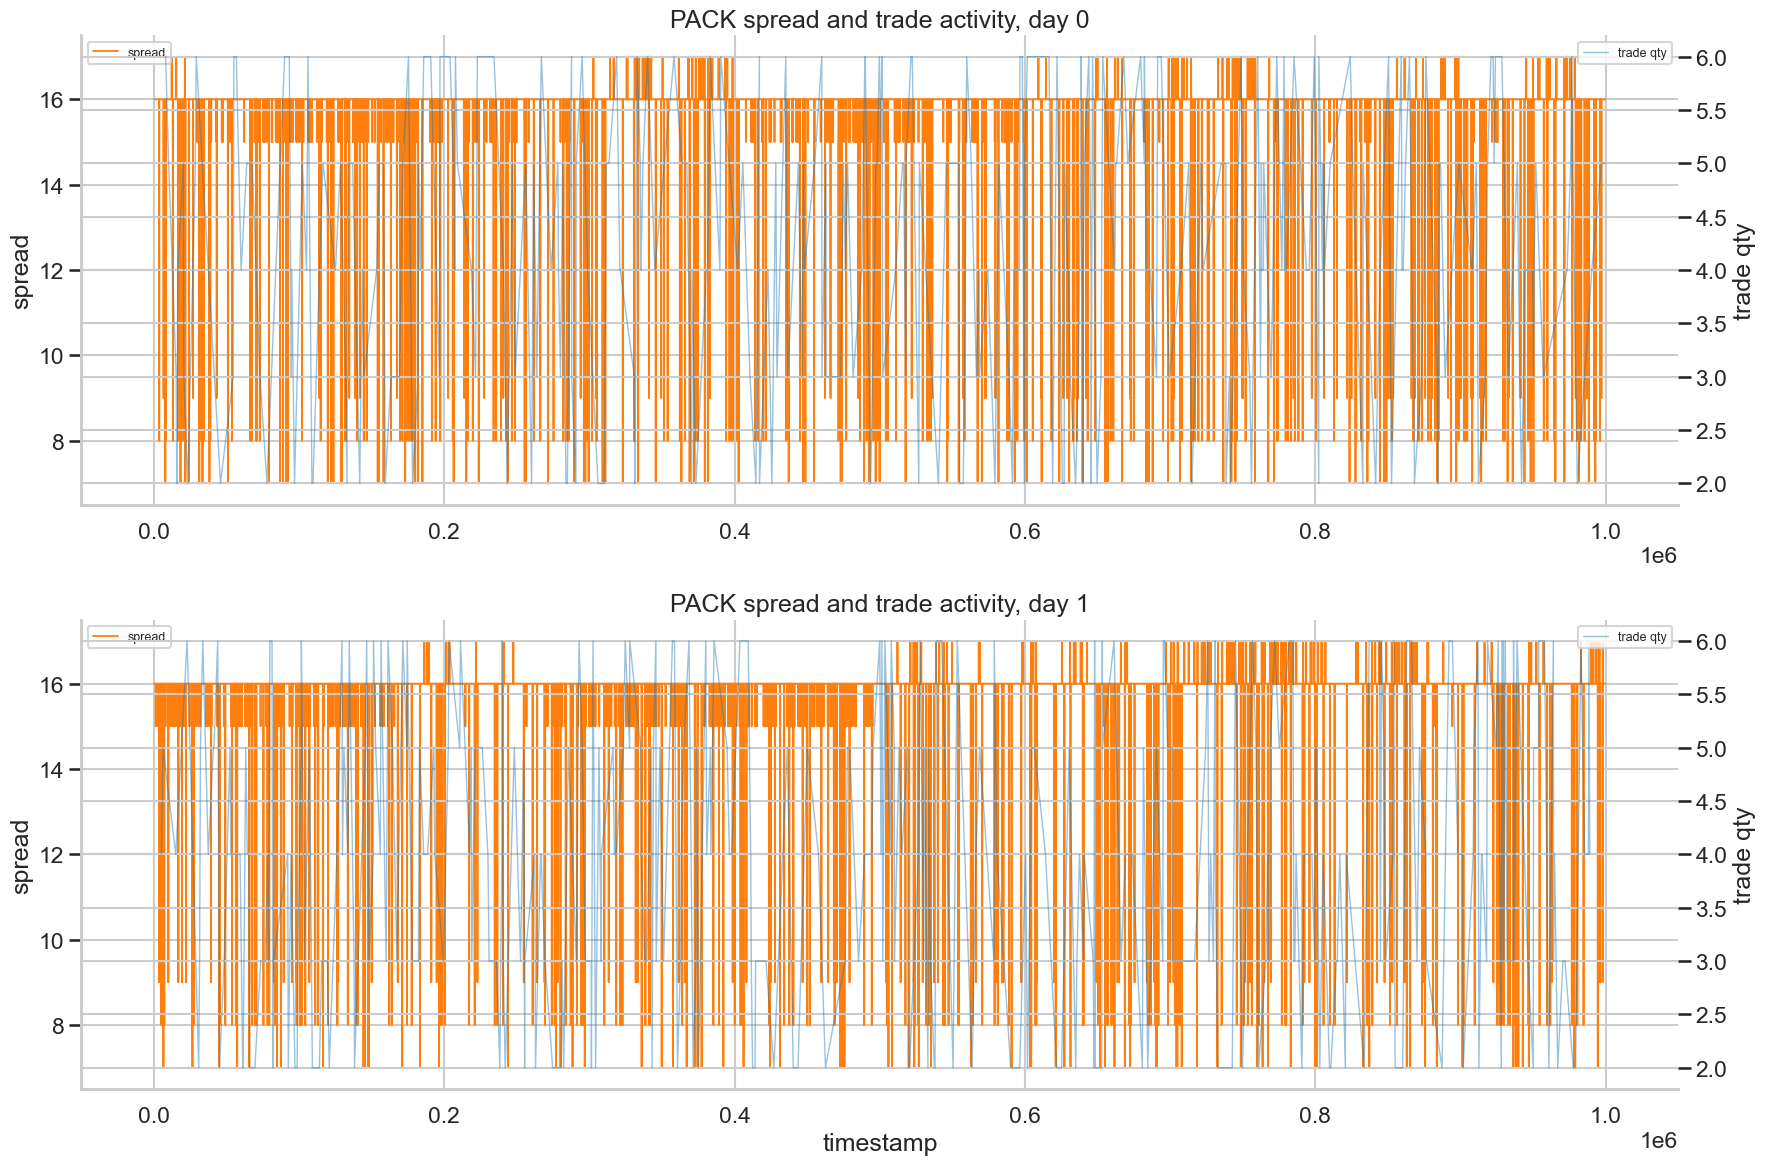

In [18]:
window = 50
fig, axes = plt.subplots(len(days), 1, figsize=(18, 14), sharex=False)

for ax, day in zip(axes, days):
    day_prices = book.loc[book['day'] == day].copy()
    day_prices['rolling_mid'] = day_prices['mid_price'].rolling(window=window, min_periods=10, center=True).mean()
    day_prices['rolling_vol'] = day_prices['mid_price'].rolling(window=window, min_periods=10, center=True).std()

    ax.plot(day_prices['timestamp'], day_prices['mid_price'], color='lightgray', lw=0.9, label='mid')
    ax.plot(day_prices['timestamp'], day_prices['rolling_mid'], color='#9467bd', lw=2.0, label=f'rolling mean ({window})')
    ax.fill_between(
        day_prices['timestamp'],
        day_prices['rolling_mid'] - day_prices['rolling_vol'].fillna(0),
        day_prices['rolling_mid'] + day_prices['rolling_vol'].fillna(0),
        color='#9467bd',
        alpha=0.12,
        label='rolling +/- std' if day == days[0] else None,
    )
    ax.set_title(f'PACK rolling trend and volatility proxy, day {day}')
    ax.set_ylabel('price')
    ax.legend(loc='upper left', fontsize=9)

axes[-1].set_xlabel('timestamp')
plt.tight_layout()

activity = trade_mid.groupby(['day', 'timestamp']).agg(
    trade_qty=('quantity', 'sum'),
    trade_count=('quantity', 'size'),
    notional=('notional', 'sum'),
).reset_index()
activity['vwap'] = activity['notional'] / activity['trade_qty']

fig, axes = plt.subplots(len(days), 1, figsize=(18, 12), sharex=False)
for ax, day in zip(axes, days):
    day_prices = book.loc[book['day'] == day]
    day_activity = activity.loc[activity['day'] == day]
    ax.plot(day_prices['timestamp'], day_prices['spread'], color='#ff7f0e', lw=1.3, label='spread')
    ax2 = ax.twinx()
    ax2.plot(day_activity['timestamp'], day_activity['trade_qty'], color='#1f77b4', lw=1.0, alpha=0.45, label='trade qty')
    ax.set_title(f'PACK spread and trade activity, day {day}')
    ax.set_ylabel('spread')
    ax2.set_ylabel('trade qty')
    ax.legend(loc='upper left', fontsize=9)
    ax2.legend(loc='upper right', fontsize=9)

axes[-1].set_xlabel('timestamp')
plt.tight_layout()

,mean,std,min,max
day,,,,
0,-0.5465,20.209287,-45.0,58.0
1,0.5465,20.209287,-58.0,45.0


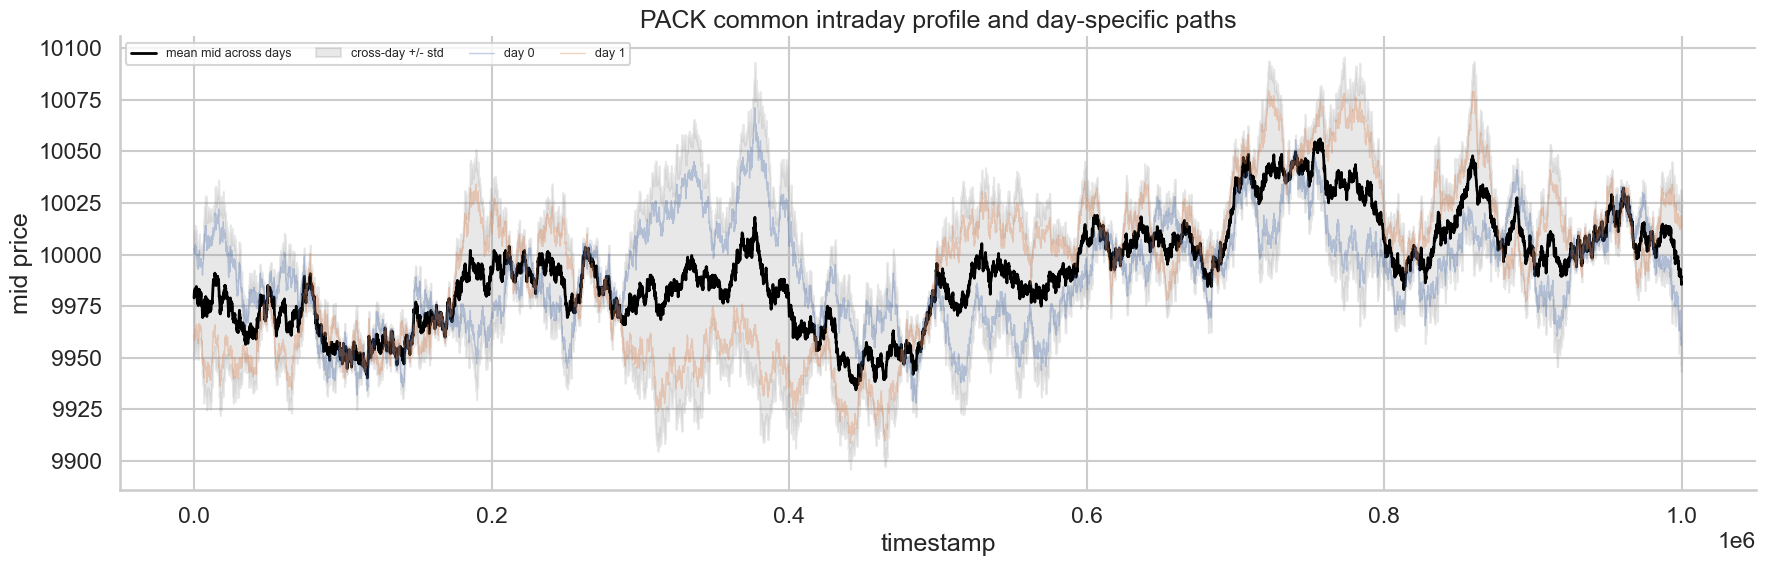

In [19]:
profile = book.groupby('timestamp').agg(
    mean_mid=('mid_price', 'mean'),
    std_mid=('mid_price', 'std'),
    mean_spread=('spread', 'mean'),
).reset_index()
profile['std_mid'] = profile['std_mid'].fillna(0)

fig, ax = plt.subplots(figsize=(18, 6))
ax.plot(profile['timestamp'], profile['mean_mid'], color='black', lw=2, label='mean mid across days')
ax.fill_between(
    profile['timestamp'],
    profile['mean_mid'] - profile['std_mid'],
    profile['mean_mid'] + profile['std_mid'],
    color='gray',
    alpha=0.18,
    label='cross-day +/- std',
)
for day in days:
    day_prices = book.loc[book['day'] == day]
    ax.plot(day_prices['timestamp'], day_prices['mid_price'], alpha=0.35, lw=1.0, label=f'day {day}')
ax.set_title('PACK common intraday profile and day-specific paths')
ax.set_xlabel('timestamp')
ax.set_ylabel('mid price')
ax.legend(ncol=4, fontsize=9)
plt.tight_layout()

residual_profile = book.assign(residual=book['mid_price'] - book.groupby('timestamp')['mid_price'].transform('mean'))
residual_summary = residual_profile.groupby('day')['residual'].agg(['mean', 'std', 'min', 'max'])
display(residual_summary)

day,0,1
lag,,
1,0.996258,0.998369
2,0.993547,0.997143
3,0.990900,0.995879
4,0.988234,0.994634
5,0.985583,0.993407
6,0.982961,0.992166
7,0.980397,0.990907
8,0.977874,0.989689
9,0.975333,0.988448


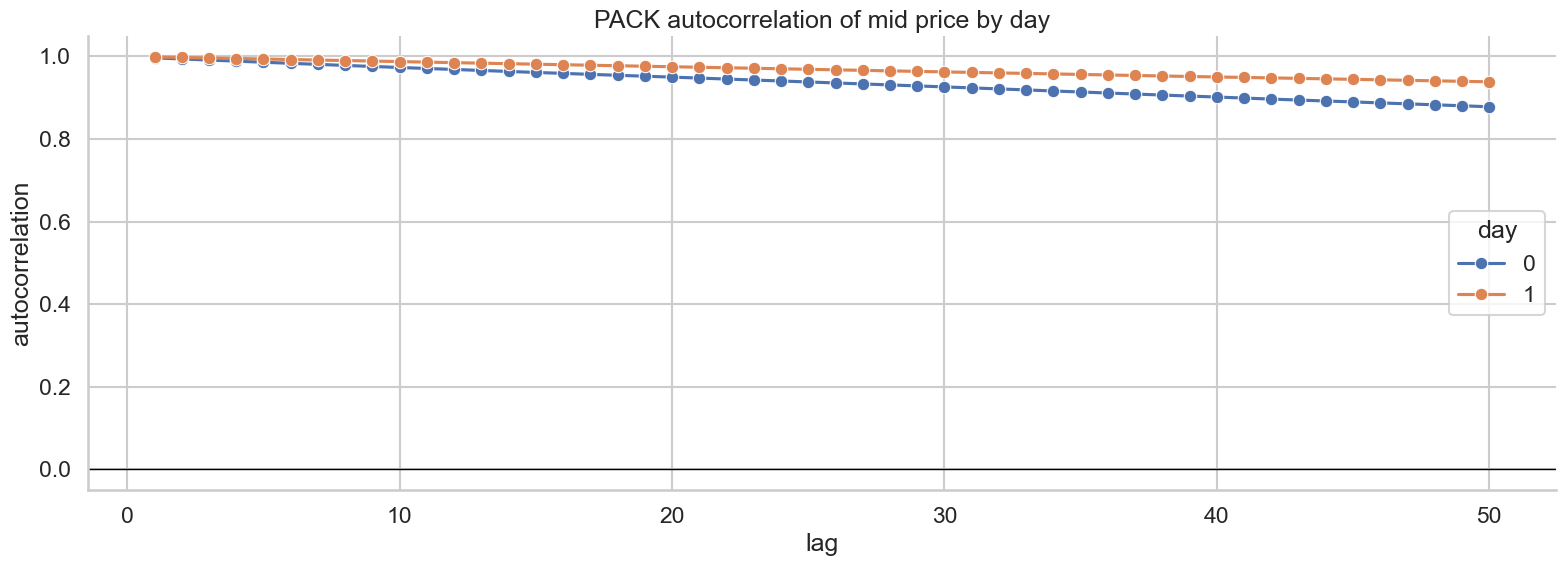

In [20]:
lags = range(1, 51)
acf_rows = []
for day, day_prices in book.groupby('day'):
    series = day_prices['mid_price'].reset_index(drop=True)
    acf_rows.extend(
        {'day': day, 'lag': lag, 'autocorr': series.autocorr(lag=lag)}
        for lag in lags
    )
acf_df = pd.DataFrame(acf_rows)

fig, ax = plt.subplots(figsize=(16, 6))
sns.lineplot(data=acf_df, x='lag', y='autocorr', hue='day', marker='o', ax=ax)
ax.axhline(0, color='black', lw=1)
ax.set_title('PACK autocorrelation of mid price by day')
ax.set_xlabel('lag')
ax.set_ylabel('autocorrelation')
plt.tight_layout()

display(acf_df.pivot(index='lag', columns='day', values='autocorr').head(15))

In [21]:
feature_table = book.groupby('day').agg(
    observations=('timestamp', 'size'),
    mean_mid=('mid_price', 'mean'),
    std_mid=('mid_price', 'std'),
    mean_abs_mid_change=('mid_change', lambda s: s.abs().mean()),
    mean_abs_pct_change=('pct_change', lambda s: s.abs().mean()),
    zero_mid_change_rate=('mid_change', lambda s: (s == 0).mean()),
    mean_spread=('spread', 'mean'),
    mean_imbalance=('imbalance', 'mean'),
).reset_index()

corr_rows = []
for day, day_prices in book.groupby('day'):
    valid = day_prices[['imbalance', 'next_mid_change', 'microprice', 'mid_price']].dropna()
    corr_rows.append({
        'day': day,
        'corr_imbalance_next_mid': valid['imbalance'].corr(valid['next_mid_change']),
        'corr_microprice_mid': valid['microprice'].corr(valid['mid_price']),
        'corr_spread_abs_change': day_prices['spread'].corr(day_prices['mid_change'].abs()),
    })
corr_table = pd.DataFrame(corr_rows)

busiest = trade_mid.groupby(['day', 'timestamp']).agg(
    trade_count=('quantity', 'size'),
    trade_qty=('quantity', 'sum'),
).sort_values(['trade_qty', 'trade_count'], ascending=False).head(10)

print('Derived feature table:')
display(feature_table)
print('Lag / price relationship table:')
display(corr_table)
print('Busiest PACK timestamps by traded quantity:')
display(busiest)

Derived feature table:


,day,observations,mean_mid,std_mid,mean_abs_mid_change,mean_abs_pct_change,zero_mid_change_rate,mean_spread,mean_imbalance
0,0,10000,9990.9621,25.328358,1.676568,0.000168,0.1861,15.7010,0.000862
1,1,10000,9992.0551,37.613011,1.650965,0.000165,0.1736,15.7264,-0.000181


Lag / price relationship table:


,day,corr_imbalance_next_mid,corr_microprice_mid,corr_spread_abs_change
0,0,0.299818,0.999958,-0.312265
1,1,0.297336,0.999981,-0.300998


Busiest PACK timestamps by traded quantity:


trade_count  trade_qty
day timestamp                        
0   8000                 1          6
    29100                1          6
    55000                1          6
    56700                1          6
    90000                1          6
    93200                1          6
    106100               1          6
    175300               1          6
    185800               1          6
    190600               1          6

## What to inspect next

- Whether PACK stays anchored near a stable mid or shows day-level drift.
- Whether spread stays narrow most of the day, with activity clustering around specific timestamps.
- Whether the common intraday profile is strong enough to separate a day-specific residual from the shared shape.
- Whether imbalance or microprice gives a useful hint about the next mid move.